### Model inspired by:

- [1] Offshore Pipelaying Dynamics. Gullik Anthon Jensen
- [2] A nonlinear PDE formulation for offshore vessel pipeline installation. Gullik A. Jensen et al
- [3] Modeling and Control of Offshore Pipelay Operations Based on a Finite Strain Pipe Model. Gullik A. Jensen

### Implementation aspects:

- The model can be applied to normal dynamic pipelay condition as a rough estimate
- v32c: sign convention of weight/vessel force fixed (pipe now in tension), node-0 clamp in the static solve, lumped consistent mass,
  tangent-frame drag, midpoint strain/curvature, Fossen Coriolis, torque-space rotational basis, realistic forcing + tolerances.


In [1]:
import numpy as np
import inspect
import matplotlib.pyplot as plt
import scipy
from datetime import datetime
from scipy.optimize import root
from scipy.integrate import solve_ivp
from scipy import interpolate
import plotly.graph_objects as go
from scipy.interpolate import interp1d
from scipy import integrate
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.spatial.transform import Rotation as Rot

### Input data:

In [2]:
mp = 125.90     #  (submerged pipe weight) [kg/m]
N = 14    # number of modelling nodes

In [3]:
d = 320      # Water depth [m]

In [4]:
qw = 1025 # Water density [kg/m3]
d0 = 0.762 # Outer diameter of pipe, [m]
dI = (762-33*2)/1000 # Inner diameter of pipe, [m]

In [5]:
# Underwater current: 
dv1_curr = 0
dv2_curr = 0
dv3_curr = 0

In [6]:
Fx_0 = 2600*1000

In [7]:
E = 207e9
G = 79.3e9
nu_p = 0.3

In [8]:
# Vessel model from Thor I. Fossen - MSS - 'rig.m'

In [9]:
# integration parameters
tspan = (0.,3.)

### Main functions:

In [10]:
A = np.pi * ((d0/2)**2 - (dI/2)**2)

In [11]:
m = (dI/2)/ (d0/2)
m2 = m**2
k_shear = (6.0 * (1.0 + nu_p) * (1.0 + m2)**2) / (
    (7.0 + 6.0 * nu_p) * (1.0 + m2)**2 + (20.0 + 12.0 * nu_p) * m2)

In [12]:
A2 = k_shear * A
A3 = k_shear * A

In [13]:
J = (np.pi / 2.0) * ((d0/2)**4 - (dI/2)**4)

In [14]:
J1 = J

In [15]:
J2 = (np.pi / 64) * (d0**4 - dI**4)
J3 = J2

In [16]:
I1=(1/2)*mp*((d0/2)**2+(dI/2)**2)

In [17]:
I2 = (1/12)*mp*(3*(d0/2)**2+3*(dI/2)**2)
I3 = I2

In [18]:
I1, I3

(16.761381749999998, 8.380690875)

In [19]:
def Ret_e_t(φ,θ,ψ):
    Cφ=np.array([[1,0,0],
                  [0,np.cos(φ),-np.sin(φ)],
                  [0,np.sin(φ),np.cos(φ)]])

    Cθ=np.array([[np.cos(θ),0,np.sin(θ)],
                  [0,1,0],
                  [-np.sin(θ),0,np.cos(θ)]])

    Cψ=np.array([[np.cos(ψ),-np.sin(ψ),0],
                  [np.sin(ψ),np.cos(ψ),0],
                  [0,0,1]])

    return Cθ @ Cφ @ Cψ   

In [20]:
def Πe(φ, θ, ψ):
    return np.array([
        [ np.cos(θ), 0, np.cos(φ) * np.sin(θ)], 
        [         0, 1, -np.sin(φ)], 
        [-np.sin(θ), 0, np.cos(φ) * np.cos(θ)]
    ]) 

In [21]:
def dΠ(φ, θ, ψ, dφ, dθ, dψ):
    return np.array([[-np.sin(θ)*dθ,0,-np.sin(φ)*dφ*np.sin(θ)+np.cos(φ)*np.cos(θ)*dθ],
                  [0,0,-np.cos(φ)*dφ],
                  [-np.cos(θ)*dθ,0,-np.sin(φ)*dφ*np.cos(θ)-np.cos(φ)*np.sin(θ)*dθ]])

In [22]:
diag_J_t_rho = np.array([I1, I2, I3])      
J_t_rho = np.diag(diag_J_t_rho)

In [23]:
diag_CT = np.array([E*A, G*A2, G*A3])
CT=np.diag(diag_CT) 

In [24]:
diag_CR = np.array([G*J, E*J2, E*J3]) 
CR=np.diag(diag_CR) 

In [25]:
Cd_axial  = 0.05   # axial (skin-friction type) drag coefficient; was 1.5 (far too high for the tangent direction)
Cd_normal = 1.5    # cross-flow drag coefficient (as before)
diag_DT = np.array([Cd_axial, Cd_normal, Cd_normal])
DT=np.diag(diag_DT)

In [26]:
diag_DR = 1.5*np.array([1, 1, 1])  
DR=np.diag(diag_DR)

In [27]:
def I_e_rho(φ,θ,ψ):
    return Ret_e_t(φ,θ,ψ) @ J_t_rho @ Ret_e_t(φ,θ,ψ).T

In [28]:
def phi(x,y,z): return np.array([x,y,z]) 
def theta(φ,θ,ψ): return np.array([φ,θ,ψ]) 

In [29]:
def d_s_theta(φ1,θ1,ψ1,φ2,θ2,ψ2,h):
    return  1/h*(theta(φ2,θ2,ψ2) - theta(φ1,θ1,ψ1)) 

In [30]:
def S(a1, a2, a3 ):
    return np.array([[0, -a3, a2 ],
                         [a3, 0, -a1],
                        [-a2, a1, 0]])

In [31]:
def d_s_phi(x1,y1,z1,x2,y2,z2, h):
    return 1/h*(phi(x2,y2,z2)-phi(x1,y1,z1))

In [32]:
def ne(x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h):
    # evaluated at the element midpoint: orientation = average of the two node angles
    Rm = Ret_e_t(0.5*(φ1+φ2), 0.5*(θ1+θ2), 0.5*(ψ1+ψ2))
    res = Rm @ CT @ Rm.T @ (
        d_s_phi(x1,y1,z1,x2,y2,z2,h).flatten()
        - Rm @ np.array([1,0,0])
    )
    return res.flatten()

In [33]:
def me(φ1, θ1, ψ1, φ2, θ2, ψ2, h):
    φm, θm, ψm = 0.5*(φ1+φ2), 0.5*(θ1+θ2), 0.5*(ψ1+ψ2)
    kappa_e = Πe(φm, θm, ψm) @ d_s_theta(φ1, θ1, ψ1, φ2, θ2, ψ2, h)
    Rm = Ret_e_t(φm, θm, ψm)
    return Rm @ CR @ Rm.T @ kappa_e

In [34]:
fe_g = np.array([0,0, -mp*9.81])

In [35]:
def f_t_d(R, dx, dy, dz):
    """Drag force in the TANGENT frame. R = Ret_e_t (tangent->global). Velocities dx,dy,dz are global."""
    v_rel_e = np.array([dx - dv1_curr, dy - dv2_curr, dz - dv3_curr])
    vr1, vr2, vr3 = R.T @ v_rel_e            # relative velocity in the tangent frame
    vn = np.sqrt(vr2**2 + vr3**2)
    A = np.array([np.abs(vr1) * vr1, vn * vr2, vn * vr3])
    return 0.5 * d0 * qw * (DT @ A)          # caller rotates back with R

In [36]:
def sigma(x,y,z):
    e3 = np.array([0,0,1])
    
    k = -(phi(x,y,z) @ e3)+d0/2
    
    fe_g2 = np.linalg.norm(fe_g, ord=2)
   
    if k<0:
        k0=0
    elif 0<=k<=d0/20:
        k0=(fe_g2*10*k**2)/((d0/8-d0/40)*(d0))
    else:
        k0=(fe_g2*(k-d0/40))/(d0/8-d0/40)
            
    result = - k0 * e3 
   
    return result  

In [37]:
def coriolis_matrix(M, nu):
    """Fossen (2011) Coriolis/centripetal matrix C(nu) for a 6-DOF body (valid for M_RB and M_A)."""
    M11, M12, M21, M22 = M[:3,:3], M[:3,3:], M[3:,:3], M[3:,3:]
    nu1, nu2 = nu[:3], nu[3:]
    a = M11 @ nu1 + M12 @ nu2
    b = M21 @ nu1 + M22 @ nu2
    Cm = np.zeros((6, 6))
    Cm[:3, 3:] = -S(*a)
    Cm[3:, :3] = -S(*a)
    Cm[3:, 3:] = -S(*b)
    return Cm

In [38]:
class MyTime:
    def __init__(self):
        self.progression = [i for i in range(650)]
        self.wall_clock = datetime.now()
        self.top_tension = -float('inf')
        self.sagbend_strain = -float('inf')
        self.my_iter = 0
        
        # Vessel from Thor I. Fossen - MSS
        self.MRB = 1.0e+10 * np.array([[0.0027  ,       0   ,      0     ,    0  , -0.0530    ,     0],
                                [0 ,   0.0027 ,        0 ,   0.0530  ,       0 ,  -0.0014],
                                [0 ,        0  ,  0.0027,         0 ,   0.0014 ,        0],
                                [0,    0.0530   ,      0,    3.4775 ,        0,   -0.0265],
                                [-0.0530 ,        0 ,   0.0014 ,        0,    3.8150,         0],
                                [0,   -0.0014 ,        0,   -0.0265 ,        0 ,   3.7192]])
        
        
        self.MA = 1.0e+10 * np.array([[0.0017,         0,         0,         0,   -0.0255,         0],
                                [0 ,   0.0042  ,       0 ,   0.0365  ,       0  ,       0],
                                [0   ,      0  ,  0.0021 ,        0   ,      0 ,        0],
                                [0 ,   0.0365 ,        0,    1.3416 ,        0  ,       0],
                                [-0.0255,         0,         0 ,        0,    2.2267 ,        0],
                                [0,         0,         0 ,        0,         0 ,   3.2049]])
        
        self.M = self.MRB + self.MA

        self.CRB = coriolis_matrix
        
        self.CA = coriolis_matrix

        self.D = 1.0e+09 * np.array([[0.0004,         0,         0,         0,   -0.0085,         0],
                                [0,    0.0003,         0,    0.0067,         0,   -0.0002],
                                [0       ,  0   , 0.0034   ,      0   , 0.0017 ,        0],
                                [0 ,   0.0067 ,        0,    4.8841,         0,   -0.0034],
                                [-0.0085  ,       0 ,   0.0017  ,       0  ,  7.1383 ,        0],
                                [0,   -0.0002 ,        0,   -0.0034 ,        0,    0.8656]])

        self.G = 1.0e+10 * np.array([[0,         0 ,        0,         0,         0 ,        0],
                                [0 ,        0,         0,         0 ,        0,         0],
                                [0 ,        0 ,   0.0006 ,        0,         0 ,        0],
                                [0 ,        0 ,        0,    1.4296 ,        0,         0],
                                [0 ,        0 ,        0 ,        0,    2.6212,         0],
                                [0  ,       0  ,       0 ,        0   ,      0 ,        0 ]])

### Static solution

In [39]:
mi = [mp for i in range(N)]

In [40]:
pipe_weight_per_unit_length = mi #  (submerged) [kg/m]  

In [41]:
Ws = np.array(pipe_weight_per_unit_length)*9.81 # [N/m]

In [42]:
def catenary_z(x, w, Tx):
    a = Tx / w
    return a * (np.cosh(x / a) - 1.0)

def catenary_length(x, w, Tx):
    a = Tx / w
    return a * np.sinh(x / a)

# Inputs
w = Ws[0]       # Effective submerged weight [N/m]
Tx = Fx_0 - w*d   # Horizontal tension [N]: top tension Fx_0 = Tx + w*d (was Tx = Fx_0, i.e. 4% too long / 20 m too deep)

# Calculate LTD from target water depth
a = Tx / w
LTD = a * np.arccosh(1.0 + d / a)

# Calculate profile
x0 = np.linspace(0.0, LTD, N)
z0 = catenary_z(x0, w, Tx)
s0 = catenary_length(x0, w, Tx)

print(f"LTD: {LTD:.2f} m")
print(f"Depth at vessel: {z0[-1]:.2f} m (target: {d:.2f} m)")
print(f"Total suspended pipe length: {s0[-1]:.2f} m")

LTD: 1053.51 m
Depth at vessel: 320.00 m (target: 320.00 m)
Total suspended pipe length: 1115.74 m


In [43]:
h = s0[-1]/(N-1)

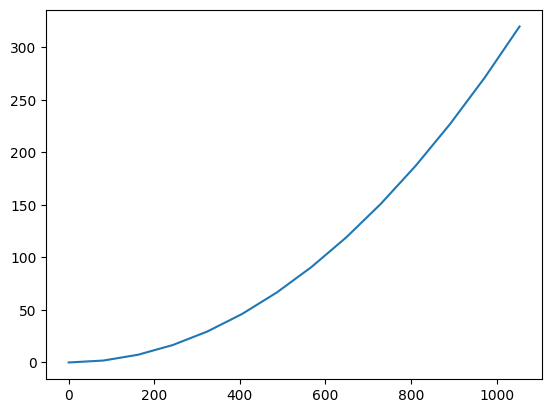

In [44]:
plt.plot(x0, z0)
plt.show()

In [45]:
q0=np.zeros(12*N)

In [46]:
theta0 = np.zeros(N)

for i in range(N):
    if i == 0:
        dzdx = (z0[1] - z0[0]) / (x0[1] - x0[0])
    elif i == N-1:
        dzdx = (z0[-1] - z0[-2]) / (x0[-1] - x0[-2])
    else:
        dzdx = (z0[i+1] - z0[i-1]) / (x0[i+1] - x0[i-1])

    theta0[i] = -np.arctan2(dzdx, 1.0)

In [47]:
q0[0*N:1*N] = x0
q0[2*N:3*N] = 0.0
q0[4*N:5*N] = z0

q0[6*N:7*N] = 0.0       # phi
q0[8*N:9*N] = theta0    # theta
q0[10*N:11*N] = 0.0     # psi

In [48]:
def fun1_1(x_int,φ,θ,ψ,t):
    """Lumped mass block, right-node test function N2=(1+xi)/2 (element j-1,j).
    Rotational block is Ie@Pi (torque space), consistent with the other rotational rows."""
    def f_(xi):
        w = 1/2*(1+xi)
        A = mp*w*np.identity(3)
        D = w*(I_e_rho(φ,θ,ψ) @ Πe(φ, θ, ψ))
        return h/2*np.block([[A, np.zeros((3,3))], [np.zeros((3,3)), D]])
    res = np.array([f_(xi) for xi in x_int])
    return np.moveaxis(res, 0, -1)


def fun1_2(x_int,φ,θ,ψ,t):
    """Lumped mass block, left-node test function N1=(1-xi)/2 (element j,j+1)."""
    def f_(xi):
        w = 1/2*(1-xi)
        A = mp*w*np.identity(3)
        D = w*(I_e_rho(φ,θ,ψ) @ Πe(φ, θ, ψ))
        return h/2*np.block([[A, np.zeros((3,3))], [np.zeros((3,3)), D]])
    res = np.array([f_(xi) for xi in x_int])
    return np.moveaxis(res, 0, -1)


def fun2_1(x_int, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h):
    
    def fun2_1_(x_int, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h):
        A=1/h*np.identity(3)
        B=np.zeros((3,3))
        C=-1/2*(1+x_int)*S(*d_s_phi(x1, y1, z1, x2, y2, z2, h))
        return h/2*np.block([[A, B], [C, A]])@np.concatenate((np.asarray(ne(x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h)),
                                                              np.asarray(me(φ1, θ1, ψ1, φ2, θ2, ψ2, h))), axis=None)
    
    res = np.array([fun2_1_(xi, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h) for xi in x_int])
    return np.moveaxis(res, 0, -1)

    
def fun2_2(x_int, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h):
    
    def fun2_2_(x_int, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h):
        A=-1/h*np.identity(3)
        B=np.zeros((3,3))
        C=-1/2*(1-x_int)*S(*d_s_phi(x1, y1, z1, x2, y2, z2, h))
        return h/2*np.block([[A, B], [C, A]])@np.concatenate((np.asarray(ne(x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h)),
                                                              np.asarray(me(φ1, θ1, ψ1, φ2, θ2, ψ2, h))), axis=None)
    
    res = np.array([fun2_2_(xi, x1, y1, z1, φ1, θ1, ψ1, x2, y2, z2, φ2, θ2, ψ2, h) for xi in x_int])
    return np.moveaxis(res, 0, -1)    

    
def fun3_1(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
    
    def fun3_1_(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
        A=np.zeros(3)  
        B=1/2*(1+x_int)*I_e_rho(φ,θ,ψ)@dΠ(φ, θ, ψ, dφ, dθ, dψ)@np.array([dφ, dθ, dψ])
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun3_1_(xi,φ,θ,ψ, dφ, dθ, dψ,t) for xi in x_int])
    return np.moveaxis(res, 0, -1)  

    
def fun3_2(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
    
    def fun3_2_(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
        A=np.zeros(3) 
        B=1/2*(1-x_int)*I_e_rho(φ,θ,ψ)@dΠ(φ, θ, ψ, dφ, dθ, dψ)@np.array([dφ, dθ, dψ])
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun3_2_(xi,φ,θ,ψ, dφ, dθ, dψ,t) for xi in x_int])
    return np.moveaxis(res, 0, -1)    

    
def fun4_1(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
    
    def fun4_1_(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
        A=np.zeros(3)  
        B=1/2*(1+x_int)*S(*(Πe(φ, θ, ψ)@np.array([dφ, dθ, dψ])))@(I_e_rho(φ,θ,ψ)@Πe(φ, θ, ψ)@np.array([dφ, dθ, dψ])).T
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun4_1_(xi,φ,θ,ψ, dφ, dθ, dψ,t) for xi in x_int])
    return np.moveaxis(res, 0, -1)

    
def fun4_2(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
    
    def fun4_2_(x_int,φ,θ,ψ, dφ, dθ, dψ,t):
        A=np.zeros(3) 
        B=1/2*(1-x_int)*S(*(Πe(φ, θ, ψ)@np.array([dφ, dθ, dψ])))@(I_e_rho(φ,θ,ψ)@Πe(φ, θ, ψ)@np.array([dφ, dθ, dψ])).T
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun4_2_(xi,φ,θ,ψ, dφ, dθ, dψ,t) for xi in x_int])
    return np.moveaxis(res, 0, -1)    

    
def fun5_1(x_int, li):
    
    def fun5_1_(x_int, li):
        B=np.zeros(3)   
        A=1/2*(1+x_int)*fe_g*li
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun5_1_(x, li) for x in x_int])
    return np.moveaxis(res, 0, -1)

    
def fun5_2(x_int, li):
    
    def fun5_2_(x_int, li):
        B=np.zeros(3)   
        A=1/2*(1-x_int)*fe_g*li
        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun5_2_(x, li) for x in x_int])
    return np.moveaxis(res, 0, -1)    

    
def fun6_1(x_int,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ):
    
    def fun6_1_(x_int,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ):
        A=1/2*(1+x_int)* Ret_e_t(φ,θ,ψ)@f_t_d(Ret_e_t(φ,θ,ψ),dx,dy,dz)
        B=1/2*(1+x_int)* DR@ Πe(φ, θ, ψ)@  np.array([dφ, dθ, dψ])

        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)  
    
    res = np.array([fun6_1_(xi,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ) for xi in x_int])
    return np.moveaxis(res, 0, -1)


def fun6_2(x_int,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ):
    
    def fun6_2_(x_int,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ):
        A=1/2*(1-x_int)* Ret_e_t(φ,θ,ψ)@f_t_d(Ret_e_t(φ,θ,ψ),dx,dy,dz)
        B=1/2*(1-x_int)* DR@ Πe(φ, θ, ψ)@  np.array([dφ, dθ, dψ])

        return h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)
    
    res = np.array([fun6_2_(xi,φ,θ,ψ, dx, dy, dz, dφ, dθ, dψ) for xi in x_int])
    return np.moveaxis(res, 0, -1)    

    
def fun7_1(x_int,x,y,z):
   
    def fun7_1_(x_int,x,y,z):
        A=1/2*(1+x_int)*sigma(x,y,z)
        B=np.zeros(3) 

        ans=h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)

        return ans
    
    res = np.array([fun7_1_(xi,x,y,z) for xi in x_int])
    return np.moveaxis(res, 0, -1)


def fun7_2(x_int,x,y,z):
   
    def fun7_2_(x_int,x,y,z):
        A=1/2*(1-x_int)*sigma(x,y,z)
        B=np.zeros(3) 

        ans=h/2*np.concatenate((np.asarray(A), np.asarray(B)), axis=None)

        return ans
    
    res = np.array([fun7_2_(xi,x,y,z) for xi in x_int])
    return np.moveaxis(res, 0, -1)    

In [49]:
def body_frame_nu(u_dot_xyz, phi, theta, psi, dphi, dtheta, dpsi):
    """Eq. (64): rotate spatial velocity + convert Euler rates -> body-frame nu."""
    Re_b = Ret_e_t(phi, theta, psi)
    w_e  = Πe(phi, theta, psi) @ np.array([dphi, dtheta, dpsi])   # Eq. (100)
    nu_lin = Re_b.T @ np.asarray(u_dot_xyz)
    nu_ang = Re_b.T @ w_e
    return np.concatenate([nu_lin, nu_ang])


def Jt_blocks(φ, θ, ψ):
    """[v_e ; omega_e] -> body-frame nu.  (Torque-space kinematic map: no Pi^T in the angular block.)"""
    R = Ret_e_t(φ, θ, ψ)
    Z = np.zeros((3, 3))
    return np.block([[R.T, Z], [Z, R.T]])

In [50]:
ENV_SCALE_F = 1.0e5   # [N]   original amplitudes (4, 3 N) were ~1e-6 of the pipe tension -> no visible response
ENV_SCALE_M = 1.0e7   # [N m] original moment amplitude (2 N m) likewise

def environmental_force(t):
    """
    Environmental force/moment acting on vessel, body frame: [Fx, Fy, Fz, Mx, My, Mz]
    """
    Fx_env = ENV_SCALE_F * 4.0 * np.sin(2*np.pi*t/10.0+0.5)
    Fy_env = ENV_SCALE_F * 3.0 * np.sin(2*np.pi*t/12.0+0.5)
    Fz_env = 0.0
    Mx_env = 0.0
    My_env = 0.0
    Mz_env = ENV_SCALE_M * 2.0 * np.sin(2*np.pi*t/15.0+0.5)
    return np.array([Fx_env, Fy_env, Fz_env, Mx_env, My_env, Mz_env])

In [51]:
# Node 0 (touch-down end) is clamped at the initial-guess position/orientation.
# The old code left node 0 without any equation (row identically 0) -> rank-deficient system.
Q_ref0 = np.array([x0[0], 0.0, z0[0], 0.0, theta0[0], 0.0])   # [x,y,z,phi,theta,psi] of node 0
bc_scale = Fx_0     # N per m (or rad): keeps the clamp rows comparable to the force rows

def static_solution(Q, T): 
    x, y, z = Q[0:N], Q[1*N:2*N], Q[2*N:3*N]
    φ, θ, ψ = Q[3*N:4*N], Q[4*N:5*N], Q[5*N:6*N]
    
    f2 = []
    f5 = []
    f7 = []
    f8 = []
   
    for j in range(N):
        if j == N-1:
            res_f2 = integrate.fixed_quad(lambda x_int: fun2_1(x_int, x[j-1], y[j-1], z[j-1], φ[j-1], θ[j-1], ψ[j-1], x[j], y[j], z[j], φ[j], θ[j], ψ[j], h), -1.0, 1.0, n=1)[0]
            res_f5 = integrate.fixed_quad(lambda x_int: fun5_1(x_int, 1), -1.0, 1.0, n=2)[0]
            
            f2.append(res_f2)
            f5.append(res_f5)
            f7.append(np.zeros(6))
            
            # vessel pulls the pipe end with Fx_0 along the vessel x-axis:  residual term is  - F_thrust
            F_body = np.array([Fx_0, 0, 0, 0, 0, 0])
            F_generalized = Jt_blocks(φ[j], θ[j], ψ[j]).T @ (-F_body)
            f8.append(F_generalized.flatten())
        elif j==0:
            f2.append(np.zeros(6))
            f5.append(np.zeros(6))
            f7.append(np.zeros(6))
            f8.append(np.zeros(6)) 
        else:
            res_f2 = (integrate.fixed_quad(lambda x_int: fun2_1(x_int, x[j-1], y[j-1], z[j-1], φ[j-1], θ[j-1], ψ[j-1], x[j], y[j], z[j], φ[j], θ[j], ψ[j], h), -1.0, 1.0, n=1)[0]
                      + integrate.fixed_quad(lambda x_int: fun2_2(x_int, x[j], y[j], z[j], φ[j], θ[j], ψ[j], x[j+1], y[j+1], z[j+1], φ[j+1], θ[j+1], ψ[j+1], h), -1.0, 1.0, n=1)[0])
            
            res_f5 = (integrate.fixed_quad(lambda x_int: fun5_1(x_int, 1), -1.0, 1.0, n=2)[0]
                      + integrate.fixed_quad(lambda x_int: fun5_2(x_int, 1), -1.0, 1.0, n=2)[0])
            f2.append(res_f2)
            f5.append(res_f5)
            f7.append(np.zeros(6))
            f8.append(np.zeros(6)) 

    f2 = np.array(f2) 
    f5 = np.array(f5) 
    f7 = np.array(f7)
    f8 = np.array(f8)
    
    # residual of  int(psi' n) - int(psi f_ext) - F_ext = 0 :   f5 holds the *external* weight, so it is SUBTRACTED
    f_sum = (f2 - f5 
             # + f7      # seabed contact (residual-signed), still switched off
             + f8)
    # node 0: replace the (empty) equation by the clamp condition
    f_sum[0, :] = bc_scale * (np.array([x[0], y[0], z[0], φ[0], θ[0], ψ[0]]) - Q_ref0)
        
    return f_sum.flatten()

In [52]:
T_1 = MyTime()

In [53]:
q0_stat = np.concatenate((q0[0:N], q0[2*N:3*N], q0[4*N:5*N], q0[6*N:7*N], q0[8*N:9*N], q0[10*N:11*N]))

In [54]:
root_ = root(static_solution, q0_stat, 
             method='lm', 
             args=(T_1,))

In [55]:
root_

 message: The relative error between two consecutive iterates is at most 0.000000
 success: True
  status: 2
     fun: [-1.011e-11 -1.111e-10 ... -9.136e+02  2.997e-10]
       x: [-3.889e-18  8.582e+01 ... -6.097e-13 -6.001e-13]
   cov_x: [[ 1.479e-13 -4.982e-17 ...  5.884e-19  5.791e-19]
           [-4.982e-17  1.651e-06 ... -4.067e-17 -3.937e-17]
           ...
           [ 5.884e-19 -4.067e-17 ...  7.845e-09  7.721e-09]
           [ 5.791e-19 -3.937e-17 ...  7.721e-09  7.599e-09]]
  method: lm
    nfev: 1285
    fjac: [[-1.676e+11  0.000e+00 ...  0.000e+00  0.000e+00]
           [ 0.000e+00 -1.676e+11 ...  0.000e+00  0.000e+00]
           ...
           [ 0.000e+00  0.000e+00 ... -9.508e+00 -1.630e-10]
           [ 0.000e+00  0.000e+00 ...  2.168e-10 -7.519e-01]]
    ipvt: [59 62 ... 28 42]
     qtf: [ 2.918e-03  4.193e-02 ... -2.460e-07 -1.957e+04]

In [56]:
x0_, y0_, z0_, φ0_, θ0_, ψ0_ = (root_.x[:N], 
                                root_.x[1*N:2*N], 
                                root_.x[2*N:3*N], 
                                root_.x[3*N:4*N], 
                                root_.x[4*N:5*N], 
                                root_.x[5*N:6*N])

In [57]:
q0 = np.concatenate((root_.x[:N],
      np.zeros(N),
      root_.x[1*N:2*N], 
      np.zeros(N),
      root_.x[2*N:3*N],
      np.zeros(N),
      root_.x[3*N:4*N],
      np.zeros(N),
      root_.x[4*N:5*N],
      np.zeros(N),
      root_.x[5*N:6*N],
      np.zeros(N)))                                    # start from static solution

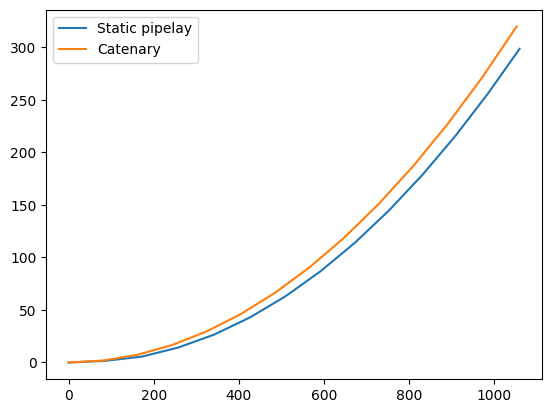

In [58]:
plt.plot(x0_, z0_, label = "Static pipelay")
plt.plot(x0, z0, label = "Catenary")
plt.legend()
plt.show()

### Dynamic Simulation

In [59]:
def dynamic_func(t, Q, T):
        
    x,y,z=Q[0:N],Q[2*N:3*N],Q[4*N:5*N]
    dx,dy,dz=Q[1*N:2*N],Q[3*N:4*N],Q[5*N:6*N]
    φ,θ,ψ=Q[6*N:7*N],Q[8*N:9*N],Q[10*N:11*N]
    dφ,dθ,dψ=Q[7*N:8*N],Q[9*N:10*N],Q[11*N:12*N]
        
    f1=[]; f2=[]; f3=[]; f4=[]; f5=[]; f6=[]; f7=[]; f8=[]
    
    for j in range(N):
        
        if j == N-1:
            # ---- vessel node: pipe end (lumped half element) + 6-DOF vessel, all in torque space ----
            qd = np.array([dφ[j], dθ[j], dψ[j]])
            R  = Ret_e_t(φ[j],θ[j],ψ[j])
            Pi = Πe(φ[j],θ[j],ψ[j])
            Jt = Jt_blocks(φ[j],θ[j],ψ[j])
            w  = np.concatenate((np.array([dx[j], dy[j], dz[j]]), Pi @ qd))   # [v_e ; omega_e]
            nu = Jt @ w                                                        # body-frame velocity
            C_nu = T.CRB(T.MRB, nu) + T.CA(T.MA, nu)
            eta = np.array([x[-1]-x0_[-1], y[-1]-y0_[-1], z[-1]-z0_[-1], φ[-1]-φ0_[-1], θ[-1]-θ0_[-1], ψ[-1]-ψ0_[-1]])
            g_eta = T.G @ eta 
            D_nu = T.D

            Z3 = np.zeros((3,3))
            Tm = np.block([[np.identity(3), Z3], [Z3, Pi]])                    # [x'' ; theta''] -> [a_e ; omega_dot] (main part)
            M_generalized = Jt.T @ T.M @ Jt @ Tm
            # nu_dot = Jt*w_dot + dJt*w ,  w_dot = [x'' ; Pi*theta'' + dPi*theta']   -> bias terms go to the force side
            dJt = np.block([[-R.T @ S(*w[3:]), Z3], [Z3, -R.T @ S(*w[3:])]])
            w_dot_bias = np.concatenate((np.zeros(3), dΠ(φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j]) @ qd))
            F_bias = T.M @ (Jt @ w_dot_bias + dJt @ w)

            f1.append(integrate.fixed_quad(lambda x_int: fun1_1(x_int, φ[j], θ[j], ψ[j],t), -1.0, 1.0, n=2)[0] + M_generalized )
            f2.append(integrate.fixed_quad(lambda x_int: fun2_1(x_int, x[j-1],y[j-1],z[j-1],φ[j-1],θ[j-1],ψ[j-1],x[j],y[j],z[j],φ[j],θ[j],ψ[j],h), -1.0,1.0,n=1)[0])
            f3.append(integrate.fixed_quad(lambda x_int: fun3_1(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0])
            f4.append(integrate.fixed_quad(lambda x_int: fun4_1(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0])
            f5.append(integrate.fixed_quad(lambda x_int: fun5_1(x_int, 1), -1.0, 1.0, n=2)[0])
            f6.append(integrate.fixed_quad(lambda x_int: fun6_1(x_int, φ[j],θ[j],ψ[j],dx[j],dy[j],dz[j],dφ[j],dθ[j],dψ[j]), -1.0, 1.0, n=2)[0])
            f7.append(np.zeros(6))

            F_env = environmental_force(t) if t>2 else np.zeros(6)
            F_thr = np.array([Fx_0, 0.0, 0.0, 0.0, 0.0, 0.0])   # station-keeping force that holds the pipe tension (acts on the vessel)

            # residual form: M a + (C+D) nu + G eta + F_bias - F_thr - F_env = 0
            F_body = g_eta + (C_nu + D_nu) @ nu + F_bias - F_thr - F_env
            f8.append(Jt.T @ F_body)

        elif j==0:
            # node 0 is clamped (zero acceleration); mass block kept so the system stays non-singular
            f1.append(integrate.fixed_quad(lambda x_int: fun1_2(x_int, φ[j], θ[j], ψ[j],t), -1.0, 1.0, n=2)[0])
            f2.append(np.zeros(6)); f3.append(np.zeros(6)); f4.append(np.zeros(6)); f5.append(np.zeros(6)); f6.append(np.zeros(6))
            f7.append(np.zeros(6)); f8.append(np.zeros(6)) 
        else:
            f1.append(integrate.fixed_quad(lambda x_int: fun1_1(x_int, φ[j], θ[j], ψ[j],t), -1.0, 1.0, n=2)[0]
                     +integrate.fixed_quad(lambda x_int: fun1_2(x_int, φ[j], θ[j], ψ[j],t), -1.0, 1.0, n=2)[0])
            f2.append(integrate.fixed_quad(lambda x_int: fun2_1(x_int, x[j-1],y[j-1],z[j-1],φ[j-1],θ[j-1],ψ[j-1],x[j],y[j],z[j],φ[j],θ[j],ψ[j],h), -1.0,1.0,n=1)[0]
                     +integrate.fixed_quad(lambda x_int: fun2_2(x_int, x[j],y[j],z[j],φ[j],θ[j],ψ[j],x[j+1],y[j+1],z[j+1],φ[j+1],θ[j+1],ψ[j+1],h), -1.0,1.0,n=1)[0])
            f3.append(integrate.fixed_quad(lambda x_int: fun3_1(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0]
                     +integrate.fixed_quad(lambda x_int: fun3_2(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0])
            f4.append(integrate.fixed_quad(lambda x_int: fun4_1(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0]
                     +integrate.fixed_quad(lambda x_int: fun4_2(x_int, φ[j],θ[j],ψ[j],dφ[j],dθ[j],dψ[j],t), -1.0, 1.0, n=2)[0])
            f5.append(integrate.fixed_quad(lambda x_int: fun5_1(x_int, 1), -1.0, 1.0, n=2)[0]
                     +integrate.fixed_quad(lambda x_int: fun5_2(x_int, 1), -1.0, 1.0, n=2)[0])
            f6.append(integrate.fixed_quad(lambda x_int: fun6_1(x_int, φ[j],θ[j],ψ[j],dx[j],dy[j],dz[j],dφ[j],dθ[j],dψ[j]), -1.0, 1.0, n=2)[0]
                     +integrate.fixed_quad(lambda x_int: fun6_2(x_int, φ[j],θ[j],ψ[j],dx[j],dy[j],dz[j],dφ[j],dθ[j],dψ[j]), -1.0, 1.0, n=2)[0])
            f7.append(np.zeros(6))
            f8.append(np.zeros(6))

    f1 = np.stack(f1, axis=0)
    f2=np.vstack(f2); f3=np.vstack(f3); f4=np.vstack(f4); f5=np.vstack(f5)
    f6=np.vstack(f6); f7=np.vstack(f7); f8=np.vstack(f8)
    
    # M a + f2 + f3 + f4 - f5 + f6 (+ f7) + f8 = 0      (f5 = external weight -> subtracted)
    f_sum = -(f2 + f3 + f4 - f5 + f6 
              # + f7 
              + f8)

    # batched solve; explicit column vector (NumPy >= 2 no longer treats (N,6) as a stack of vectors)
    X_raw = np.linalg.solve(f1, f_sum[..., None])[..., 0]
    X = X_raw.reshape(N, 6)

    ddx, ddy, ddz, ddφ, ddθ, ddψ = X.T  

    ans=np.concatenate([dx, ddx, 
                        dy, ddy,  
                        dz, ddz, 
                        dφ, ddφ,  
                        dθ, ddθ, 
                        dψ, ddψ,  
                       ], axis=0)

    if t>T.progression[0]:
        T.progression.pop(0)
        print('Physical time: ', t, ' Iteration wall-clock time: ', datetime.now() - T.wall_clock , flush=True)
        T.wall_clock = datetime.now() 
    
    T.my_iter+=1 

    if np.any(np.abs(ans) > 1e6) or np.any(np.isnan(ans)):
        print(f"\n!!! CRITICAL SYSTEM EXPLOSION AT t = {t} !!!")
        raise ValueError("Simulation aborted due to Inf/NaN generation.")

    return ans 

In [60]:
def element_resultants(q):
    """Signed axial force, bending-moment magnitude and max fibre strain per element, from a state vector q."""
    x, y, z = q[0:N], q[2*N:3*N], q[4*N:5*N]
    φ, θ, ψ = q[6*N:7*N], q[8*N:9*N], q[10*N:11*N]
    Nax = np.zeros(N-1); Mb = np.zeros(N-1)
    for e in range(N-1):
        a, b = e, e+1
        n_e = ne(x[a],y[a],z[a],φ[a],θ[a],ψ[a], x[b],y[b],z[b],φ[b],θ[b],ψ[b], h)
        m_e = me(φ[a],θ[a],ψ[a], φ[b],θ[b],ψ[b], h)
        Rm = Ret_e_t(0.5*(φ[a]+φ[b]), 0.5*(θ[a]+θ[b]), 0.5*(ψ[a]+ψ[b]))
        nt, mt = Rm.T @ n_e, Rm.T @ m_e
        Nax[e] = nt[0]                      # signed: > 0 tension
        Mb[e]  = np.hypot(mt[1], mt[2])     # resultant bending moment
    eps = Nax/(E*A) + Mb*(d0/2)/(E*J2)      # axial + bending (tension side)
    return Nax, Mb, eps

In [61]:
# --- sanity checks on the static solution (run after the static solve) ---
Nax_s, Mb_s, eps_s = element_resultants(q0)
print("axial force, element next to vessel [N]:", Nax_s[-1], " (should be ~ +Fx_0 =", Fx_0, ")")
print("min axial force over the pipe [N]      :", Nax_s.min(), " (should be > 0: tension everywhere)")
a_chk = dynamic_func(0.0, q0, MyTime())
acc = np.concatenate([a_chk[k*N:(k+1)*N] for k in (1,3,5,7,9,11)])
print("max |acceleration| at t=0 (should be ~0):", np.abs(acc).max())
print("static residual norm:", np.linalg.norm(root_.fun))

axial force, element next to vessel [N]: 2573239.446986244  (should be ~ +Fx_0 = 2600000 )
min axial force over the pipe [N]      : 2231499.4812052185  (should be > 0: tension everywhere)
max |acceleration| at t=0 (should be ~0): 0.552770839350007
static residual norm: 19568.80996089775


In [62]:
T_3 = MyTime()

In [63]:
startTime1 = datetime.now()
t_eval = np.linspace(tspan[0], tspan[1], 701)          # dense output grid (was: only the 10 internal BDF steps)
us_ = solve_ivp(dynamic_func, 
                tspan, 
                q0, 
                method='BDF',
                t_eval=t_eval,
                rtol=1e-6, atol=1e-8,                   # was default atol=1e-6, which hid all perturbations below 1e-6 m
                args=(T_3,))
print(datetime.now() - startTime1)

Physical time:  0.0007387387907731891  Iteration wall-clock time:  0:00:00.028103
Physical time:  1.0000200897367042  Iteration wall-clock time:  0:58:24.799827
Physical time:  2.0000088346852807  Iteration wall-clock time:  1:29:15.890443
4:12:33.540894


### Results

In [64]:
# number of iterations
T_3.my_iter

1373111

In [65]:
# max / min axial force (signed) from the stored solution, not from inside the RHS
res_ = [element_resultants(us_.y[:, k]) for k in range(us_.y.shape[1])]
Nax_t = np.array([r[0] for r in res_]); Mb_t = np.array([r[1] for r in res_]); eps_t = np.array([r[2] for r in res_])
print("max axial force [N]:", Nax_t.max(), "   min axial force [N]:", Nax_t.min())

max axial force [N]: 2584390.336555443    min axial force [N]: 2222972.0158998254


In [66]:
# max fibre strain (axial + bending) and max bending moment
print("max strain:", eps_t.max(), "   max bending moment [N m]:", Mb_t.max())

max strain: 0.00043954587867262214    max bending moment [N m]: 809460.6980520182


In [67]:
fin=us_

In [68]:
fin

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  4.286e-03 ...  2.996e+00  3.000e+00]
        y: [[-3.889e-18 -3.889e-18 ... -3.889e-18 -3.889e-18]
            [ 8.582e+01  8.582e+01 ...  8.582e+01  8.582e+01]
            ...
            [ 0.000e+00 -1.876e-17 ... -1.091e-04 -1.096e-04]
            [ 0.000e+00 -2.266e-22 ...  2.844e-04  2.856e-04]]
      sol: None
 t_events: None
 y_events: None
     nfev: 265121
     njev: 6556
      nlu: 25145

In [69]:
t=fin.t
fin=fin.y.T

In [70]:
t.shape, fin.shape

((701,), (701, 168))

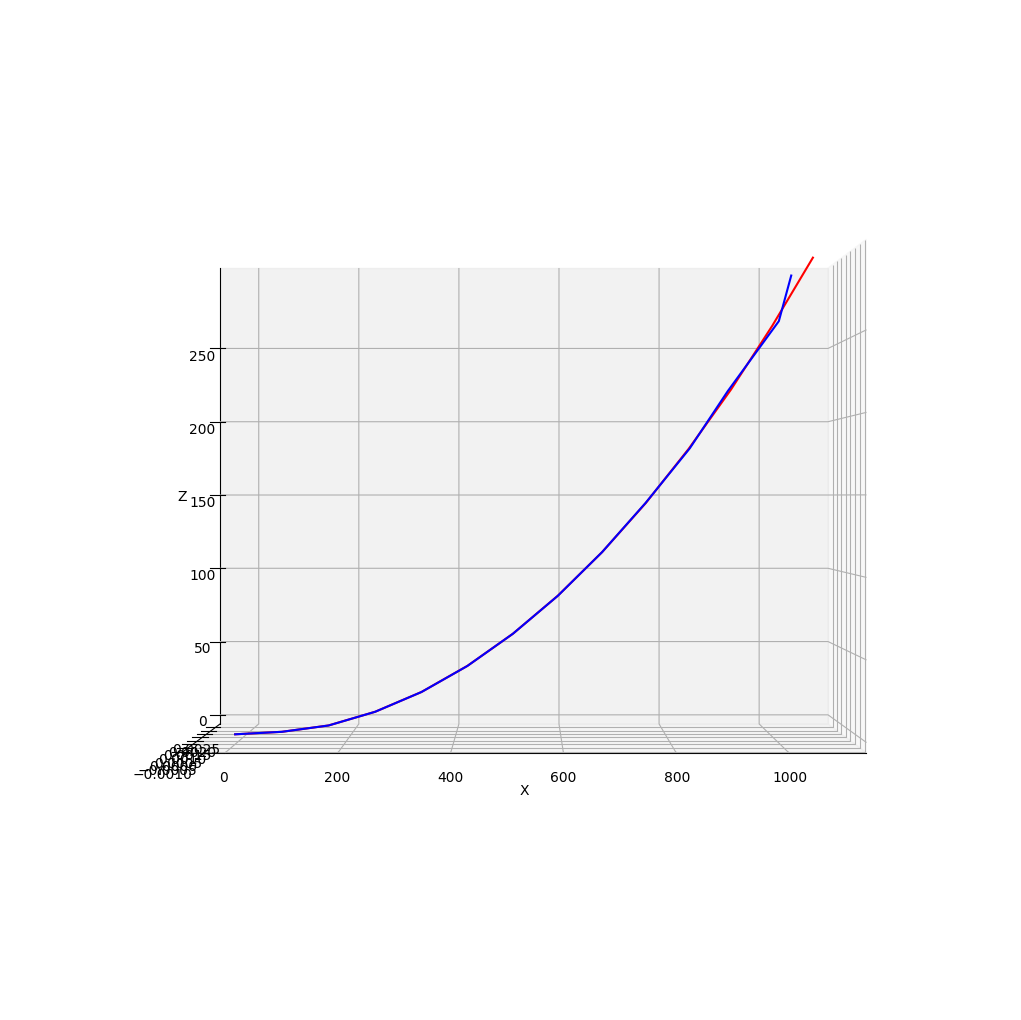

In [71]:
fig=plt.figure(figsize=(13,13))
ax = fig.add_subplot(projection = '3d')

X0=fin[0,[i for i in range(0,N)]]
Y0=fin[0,[i for i in range(2*N,3*N)]]
Z0=fin[0,[i for i in range(4*N,5*N)]]

j=-1
X=fin[j,[i for i in range(0,N)]]
Y=fin[j,[i for i in range(2*N,3*N)]]
Z=fin[j,[i for i in range(4*N,5*N)]]

num_true_pts = 200
tck, u = interpolate.splprep([X,Y,Z], s=2)
u_fine = np.linspace(0,1,num_true_pts)
x_fine, y_fine, z_fine = interpolate.splev(u_fine, tck)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.plot(X0,Y0,Z0, color='r')
ax.plot(X,Y,Z, color='b')
ax.view_init(0,-90)
plt.show()

In [72]:
X,Y,Z

(array([-3.88917038e-18,  8.58245178e+01,  1.71570339e+02,  2.56980412e+02,
         3.41921616e+02,  4.26188921e+02,  5.09634925e+02,  5.92102724e+02,
         6.73451518e+02,  7.53583491e+02,  8.32396728e+02,  9.09821320e+02,
         9.85756972e+02,  1.06027787e+03]),
 array([-4.27338210e-17,  3.80233100e-06, -4.05467942e-06,  2.80380750e-06,
        -6.82399434e-07, -3.43245415e-06,  9.11943073e-06, -1.01352997e-05,
        -6.66481868e-06,  5.80456806e-05, -2.03928471e-04,  5.34146597e-04,
        -8.79656046e-04,  2.78433940e-03]),
 array([7.17552422e-17, 1.55480853e+00, 5.54509454e+00, 1.41121981e+01,
        2.64928232e+01, 4.28429358e+01, 6.29697950e+01, 8.67902396e+01,
        1.14190150e+02, 1.44968101e+02, 1.78981728e+02, 2.16048250e+02,
        2.56077189e+02, 2.98682634e+02]))

In [73]:
X0,Y0,Z0

(array([-3.88917038e-18,  8.58245469e+01,  1.71570066e+02,  2.56979442e+02,
         3.41920232e+02,  4.26188263e+02,  5.09633182e+02,  5.92101717e+02,
         6.73461925e+02,  7.53603704e+02,  8.32416067e+02,  9.09852768e+02,
         9.85780036e+02,  1.06027242e+03]),
 array([-4.27338208e-17, -3.97415441e-11, -1.06000692e-10, -1.63280894e-10,
        -2.23139861e-10, -2.81590971e-10, -3.39795302e-10, -3.97224585e-10,
        -4.53924039e-10, -5.09769370e-10, -5.64695502e-10, -6.18668963e-10,
        -6.71594305e-10, -7.23521508e-10]),
 array([7.17552516e-17, 1.55427687e+00, 5.55147344e+00, 1.41257083e+01,
        2.65093055e+01, 4.28557664e+01, 6.29872040e+01, 8.68051699e+01,
        1.14171228e+02, 1.44923686e+02, 1.78939379e+02, 2.15980638e+02,
        2.56025516e+02, 2.98680819e+02]))

In [74]:
us=fin.T

In [75]:
us.shape

(168, 701)

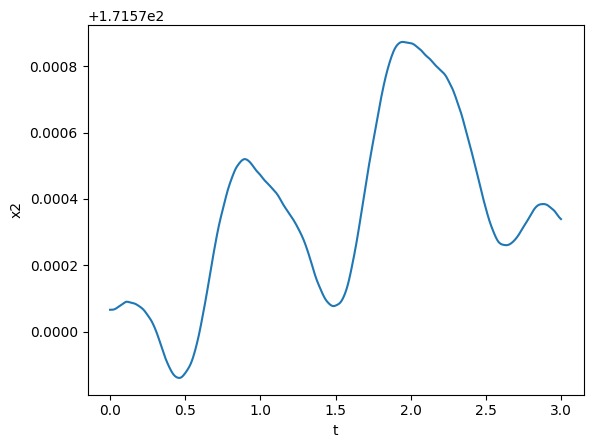

In [76]:
plt.plot(t,us.T[:,2],'-')
plt.xlabel('t')
plt.ylabel('x2')
plt.show()

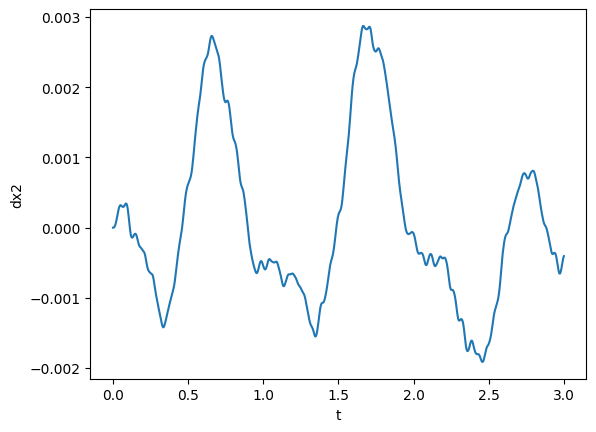

In [77]:
plt.plot(t,us.T[:,N+2] ,'-')
plt.xlabel('t')
plt.ylabel('dx2')
plt.show()

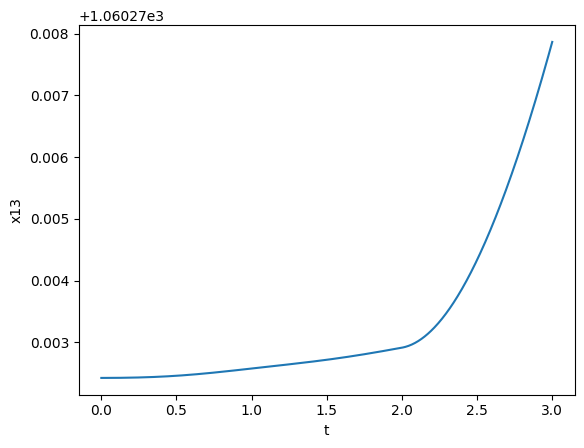

In [78]:
plt.plot(t,us.T[:,N-1] ,'-')
plt.xlabel('t')
plt.ylabel('x{}'.format(N-1))
plt.show()

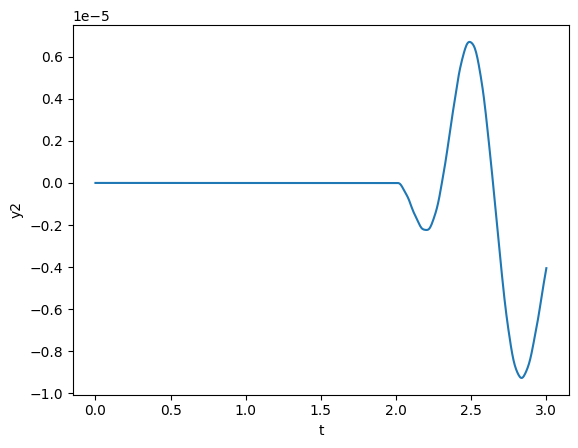

In [79]:
plt.plot(t,us.T[:,2*N +2] ,'-')
plt.xlabel('t')
plt.ylabel('y2')
plt.show()

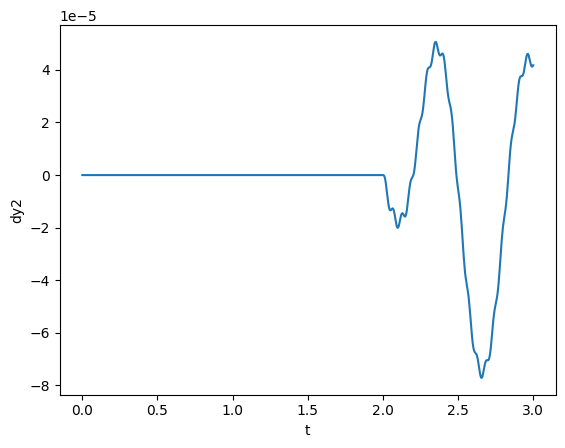

In [80]:
plt.plot(t,us.T[:,3*N+2] ,'-')
plt.xlabel('t')
plt.ylabel('dy2')
plt.show()

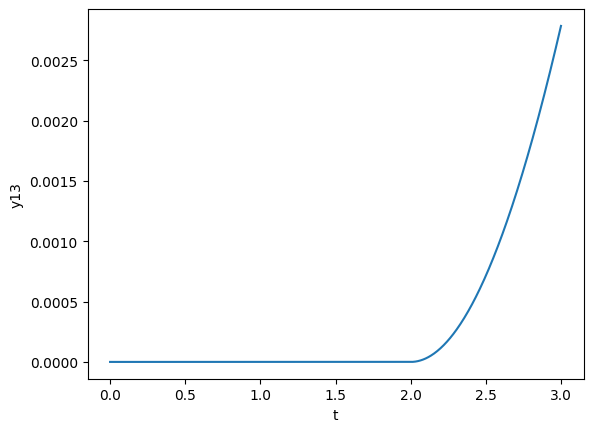

In [81]:
plt.plot(t,us.T[:,2*N+(N-1)] ,'-')
plt.xlabel('t')
plt.ylabel('y{}'.format(N-1))
plt.show()

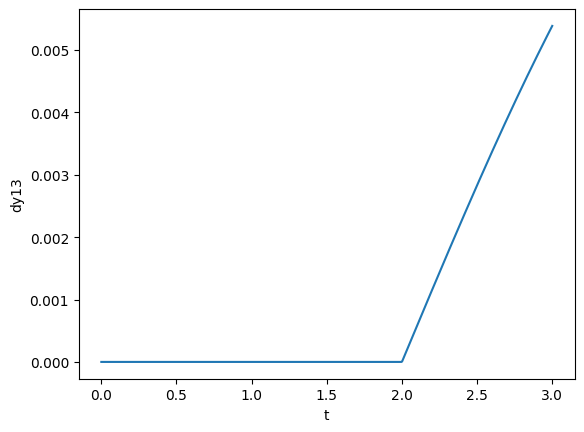

In [82]:
plt.plot(t,us.T[:,3*N+(N-1)] ,'-')
plt.xlabel('t')
plt.ylabel('dy{}'.format(N-1))
plt.show()

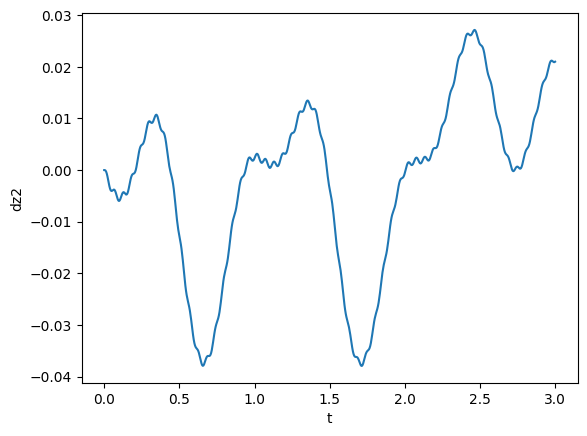

In [83]:
plt.plot(t,us.T[:,5*N+2] ,'-')
plt.xlabel('t')
plt.ylabel('dz2')
plt.show()

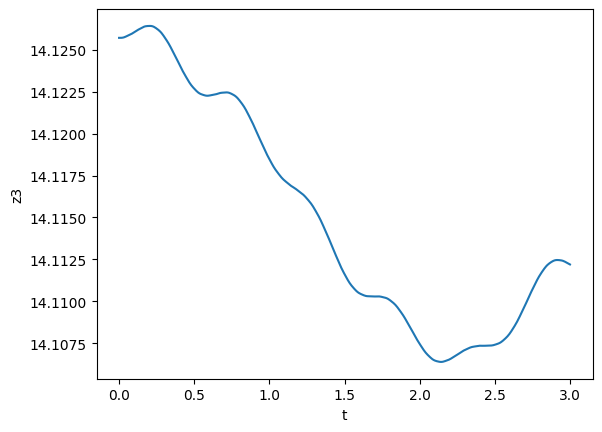

In [84]:
plt.plot(t,us.T[:,4*N+3] ,'-')
plt.xlabel('t')
plt.ylabel('z3')
plt.show()

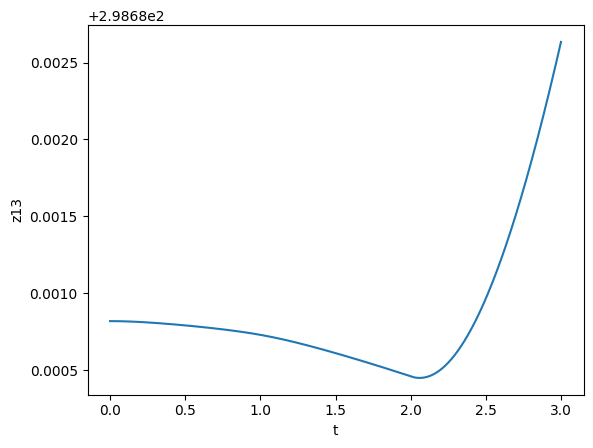

In [85]:
plt.plot(t,us.T[:,4*N + (N-1)] ,'-')
plt.xlabel('t')
plt.ylabel('z{}'.format(N-1))
plt.show()

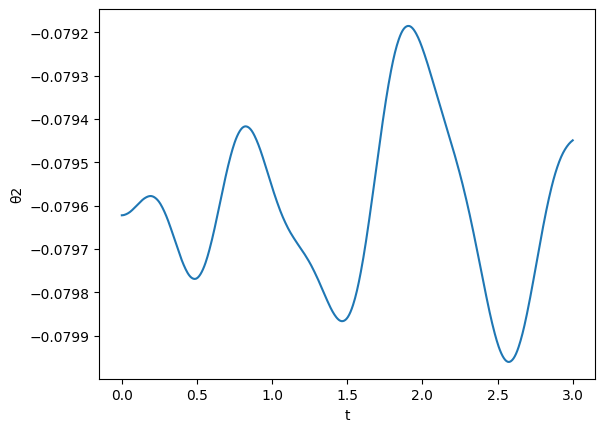

In [86]:
plt.plot(t,us.T[:,8*N+2],'-')
plt.xlabel('t')
plt.ylabel('θ2')
plt.show()

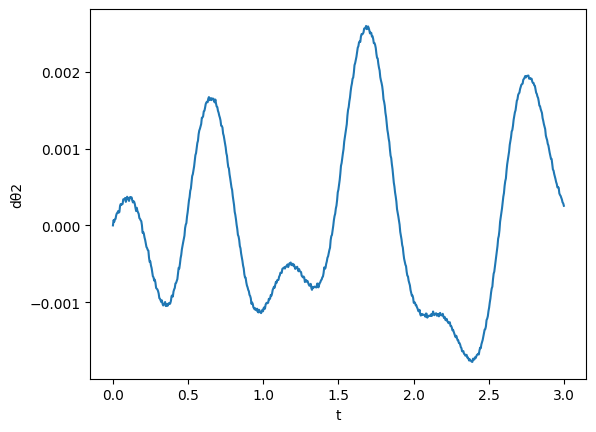

In [87]:
plt.plot(t,us.T[:,9*N+2] ,'-')
plt.xlabel('t')
plt.ylabel('dθ2')
plt.show()

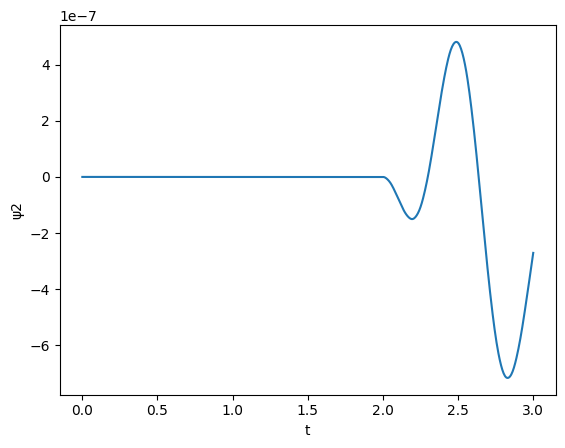

In [88]:
plt.plot(t,us.T[:,10*N+2],'-')
plt.xlabel('t')
plt.ylabel('ψ2')
plt.show()

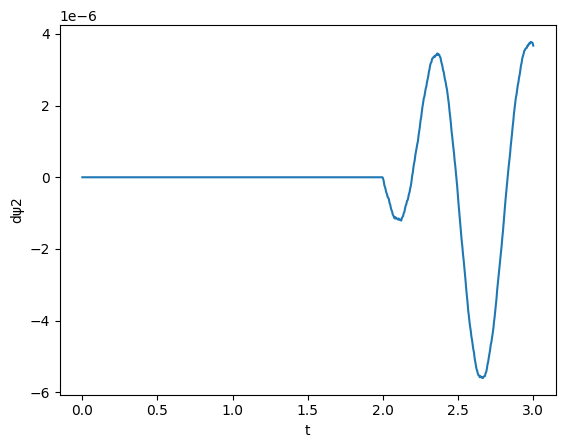

In [89]:
plt.plot(t,us.T[:,11*N+2] ,'-')
plt.xlabel('t')
plt.ylabel('dψ2')
plt.show()

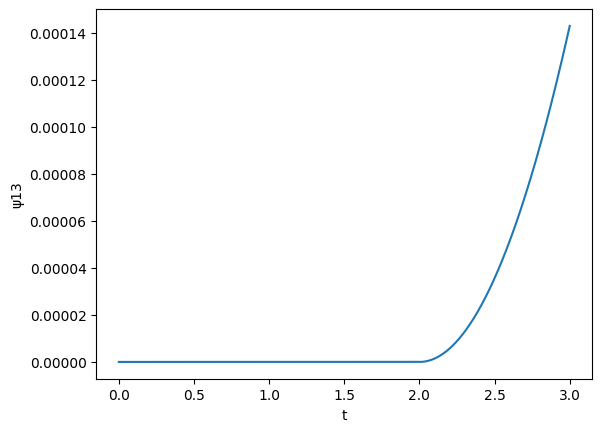

In [90]:
plt.plot(t,us.T[:,10*N + (N-1)] ,'-')
plt.xlabel('t')
plt.ylabel('ψ{}'.format(N-1))
plt.show()

In [91]:
X010=us.T[:,0*N:1*N]

In [92]:
Y010=us.T[:,2*N:3*N]

In [93]:
Z010=us.T[:,4*N:5*N]

In [94]:
# simulation = np.stack([X010, Y010, Z010], axis=2)  

# FPS = 5
# STEP = 1                      
# frame_duration = 1000 / FPS

# sim = simulation[::STEP]
# n_points = sim.shape[1]

# frames = [
#     go.Frame(
#         data=[go.Scatter3d(x=sim[t, :, 0], y=sim[t, :, 1], z=sim[t, :, 2])],
#         traces=[0],
#         name=f"t={t}",
#     )
#     for t in range(sim.shape[0])
# ]

# fig = go.Figure(
#     data=[go.Scatter3d(
#         x=sim[0, :, 0], y=sim[0, :, 1], z=sim[0, :, 2],
#         mode="lines+markers",
#         marker=dict(size=5, color=list(range(n_points)), colorscale="Viridis"),
#         line=dict(width=4),
#     )],
#     frames=frames,
# )

# fig.update_layout(
#     title="Pipelay Simulation",
#     scene=dict(
#         xaxis_title="X",
#         yaxis_title="Y",
#         zaxis_title="Z",
#         xaxis=dict(range=[0, 250], autorange=False),
#         yaxis=dict(range=[-50, 50], autorange=False),
#         zaxis=dict(range=[0, 100], autorange=False),
#         aspectmode="manual",
#         aspectratio=dict(x=4, y=1, z=1),
#         camera=dict(
#             eye=dict(x=1.5, y=-1.5, z=0.8),
#             center=dict(x=0, y=0, z=0),
#             up=dict(x=0, y=0, z=1),
#         ),
#     ),
#     uirevision="keep",
#     updatemenus=[{
#         "type": "buttons",
#         "showactive": False,
#         "buttons": [
#             {
#                 "label": "Play",
#                 "method": "animate",
#                 "args": [None, {
#                     "frame": {"duration": frame_duration, "redraw": True}, 
#                     "transition": {"duration": 0},
#                     "fromcurrent": True,
#                     "mode": "immediate",
#                 }],
#             },
#             {
#                 "label": "Pause",
#                 "method": "animate",
#                 "args": [[None], {
#                     "frame": {"duration": 0, "redraw": False},
#                     "transition": {"duration": 0},
#                     "mode": "immediate",
#                 }],
#             },
#         ],
#     }],
# )

# fig.show()

# # fig.write_html("pipe.html")